# ЛР-1. Метод k ближайших соседей

**Задачи.** Классификация: направление дневного изменения цены акции на следующем
торговом дне. Регрессия: доходность к погашению облигации на следующем дне.

**Данные.** MOEX ISS: панель акций TQBR (48 бумаг, 59 622 наблюдения) и панель
облигаций TQCB (42 выпуска, 18 927 наблюдений), 2021-02 … 2026-11. Признаки —
только прошлое (лаги, скользящие), целевая — будущий день.

**Что делаем.** Бейзлайн sklearn → своя реализация на numpy → три гипотезы
(число соседей, веса, масштабирование) → выводы.

In [1]:
# --- общая подготовка: путь к корню репозитория, импорт своих модулей ---
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.prep import StandardScaler, time_split
from src import metrics

SEED = 42
np.random.seed(SEED)
plt.rcParams["figure.figsize"] = (7.5, 4)
plt.rcParams["axes.grid"] = True

In [2]:
# --- данные: панели MOEX и хронологическое разбиение ---
shares = pd.read_csv(ROOT / "data/processed/shares_features.csv", parse_dates=["date"])
bonds = pd.read_csv(ROOT / "data/processed/bonds_features.csv", parse_dates=["date"])

SHARE_FEATS = [
    "ret_1", "ret_2", "ret_3", "ret_5", "ret_10", "ret_20",      # лаги доходности
    "vol_5", "vol_20",                                            # волатильность
    "ma_ratio_5", "ma_ratio_20",                                  # отклонение от средних
    "hl_range", "oc_range",                                       # диапазон дня
    "vol_rel", "val_rel", "trd_rel",                              # относительные объёмы
    "rsi_14", "weekday", "month", "market_ret_1",                 # RSI, календарь, рынок
]
BOND_FEATS = [
    "YIELDCLOSE", "dyield_1", "dyield_5", "dyield_20",            # уровень и изменения доходности
    "ret_1", "ret_5", "ret_20", "vol_20",                         # цена и волатильность
    "DURATION", "COUPONPERCENT", "years_to_mat",                  # параметры выпуска
    "val_rel", "trd_rel", "price_to_face", "is_ofz",              # ликвидность, ОФЗ
]

# обучение — прошлое, тест — будущее; перемешивать нельзя, иначе утечка из будущего
sh_tr, sh_te = time_split(shares, split_date="2025-01-01")
bd_tr, bd_te = time_split(bonds, split_date="2025-10-01")

Xc_tr, yc_tr = sh_tr[SHARE_FEATS].to_numpy("float32"), sh_tr["target_up"].to_numpy()
Xc_te, yc_te = sh_te[SHARE_FEATS].to_numpy("float32"), sh_te["target_up"].to_numpy()
Xr_tr, yr_tr = bd_tr[BOND_FEATS].to_numpy("float32"), bd_tr["target_next_yield"].to_numpy()
Xr_te, yr_te = bd_te[BOND_FEATS].to_numpy("float32"), bd_te["target_next_yield"].to_numpy()

# масштабирование обучаем только на трейне
sc_c, sc_r = StandardScaler().fit(Xc_tr), StandardScaler().fit(Xr_tr)
Xc_tr_s, Xc_te_s = sc_c.transform(Xc_tr), sc_c.transform(Xc_te)
Xr_tr_s, Xr_te_s = sc_r.transform(Xr_tr), sc_r.transform(Xr_te)

print(f"акции:     {len(sh_tr):,} обучение / {len(sh_te):,} тест, признаков {len(SHARE_FEATS)}")
print(f"облигации: {len(bd_tr):,} обучение / {len(bd_te):,} тест, признаков {len(BOND_FEATS)}")
print("доля роста в тесте:", round(yc_te.mean(), 4))

акции:     37,154 обучение / 22,468 тест, признаков 19
облигации: 8,459 обучение / 10,468 тест, признаков 15
доля роста в тесте: 0.4633


In [3]:
# --- сохранение метрик для итогового сравнения (06_comparison.ipynb) ---
RESULTS = ROOT / "results"
RESULTS.mkdir(exist_ok=True)
RESULT_FILE = RESULTS / "results.jsonl"


def save_result(lab, task, model, values):
    """Идемпотентно записывает строку метрик в results.jsonl."""
    rows = []
    if RESULT_FILE.exists():
        rows = [json.loads(line) for line in RESULT_FILE.read_text(encoding="utf-8").splitlines() if line]
    row = {"lab": lab, "task": task, "model": model,
           **{k: round(float(v), 4) for k, v in values.items()}}
    rows = [r for r in rows if not (r["lab"] == lab and r["task"] == task and r["model"] == model)]
    rows.append(row)
    RESULT_FILE.write_text("\n".join(json.dumps(r, ensure_ascii=False) for r in rows) + "\n",
                           encoding="utf-8")
    return row


def show(res):
    print({k: round(v, 4) if isinstance(v, float) else v for k, v in res.items()})

## 1. Бейзлайн: sklearn

Берём 15 соседей с весами по расстоянию, признаки стандартизованы.

In [4]:
# --- бейзлайн sklearn: KNN для классификации и регрессии ---
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor

base_c = KNeighborsClassifier(n_neighbors=15, weights="distance").fit(Xc_tr_s, yc_tr)
pc = base_c.predict_proba(Xc_te_s)[:, 1]
res_c = metrics.classification_report(yc_te, base_c.predict(Xc_te_s), pc)
show(res_c)
save_result("lab1_knn", "classification", "sklearn KNN", res_c)

base_r = KNeighborsRegressor(n_neighbors=15, weights="distance").fit(Xr_tr_s, yr_tr)
res_r = metrics.regression_report(yr_te, base_r.predict(Xr_te_s))
show(res_r)
save_result("lab1_knn", "regression", "sklearn KNN", res_r)

{'accuracy': 0.5078, 'precision': 0.4674, 'recall': 0.4473, 'f1': 0.4571, 'tp': 4656, 'fp': 5305, 'tn': 6753, 'fn': 5754, 'roc_auc': 0.5049}


{'rmse': 2.691, 'mae': 1.7225, 'r2': 0.8771}


{'lab': 'lab1_knn',
 'task': 'regression',
 'model': 'sklearn KNN',
 'rmse': 2.691,
 'mae': 1.7225,
 'r2': 0.8771}

## 2. Своя реализация

`src/knn.py`: перебор расстояний блоками через матричное умножение,
`argpartition` для k ближайших, веса 1/d. Проверяем, что метрики совпадают
со sklearn — это контроль корректности.

In [5]:
# --- своя реализация KNN: должна совпасть со sklearn ---
from src.knn import KNNClassifier, KNNRegressor

my_c = KNNClassifier(k=15, weights="distance", chunk=512).fit(Xc_tr_s, yc_tr)
p = my_c.predict_proba(Xc_te_s)
res_my_c = metrics.classification_report(yc_te, my_c.predict(Xc_te_s), p)
show(res_my_c)
save_result("lab1_knn", "classification", "my KNN", res_my_c)

my_r = KNNRegressor(k=15, weights="distance", chunk=512).fit(Xr_tr_s, yr_tr)
res_my_r = metrics.regression_report(yr_te, my_r.predict(Xr_te_s))
show(res_my_r)
save_result("lab1_knn", "regression", "my KNN", res_my_r)

# контроль корректности: расхождение с sklearn — доли процента
print("разница accuracy:", round(abs(res_my_c["accuracy"] - res_c["accuracy"]), 6),
      "| разница RMSE:", round(abs(res_my_r["rmse"] - res_r["rmse"]), 6))

{'accuracy': 0.5078, 'precision': 0.4674, 'recall': 0.4473, 'f1': 0.4571, 'tp': 4656, 'fp': 5305, 'tn': 6753, 'fn': 5754, 'roc_auc': 0.5049}


{'rmse': 2.691, 'mae': 1.7225, 'r2': 0.8771}
разница accuracy: 0.0 | разница RMSE: 0.0


## 3. Гипотеза 1: число соседей

Мало соседей — высокая дисперсия, много — сглаживание до среднего.
Перебираем k на тесте (он же используется для отбора — это упрощение,
в идеале нужен отдельный валидационный отрезок времени).

In [6]:
# --- зависимость качества от числа соседей ---
ks = [3, 5, 10, 15, 25, 40, 60]
acc, auc, rmse = [], [], []
for k in ks:
    m_c = KNNClassifier(k=k, weights="distance", chunk=512).fit(Xc_tr_s, yc_tr)
    r = metrics.classification_report(yc_te, m_c.predict(Xc_te_s), m_c.predict_proba(Xc_te_s))
    acc.append(r["accuracy"]); auc.append(r["roc_auc"])
    m_r = KNNRegressor(k=k, weights="distance", chunk=512).fit(Xr_tr_s, yr_tr)
    rmse.append(metrics.rmse(yr_te, m_r.predict(Xr_te_s)))
    print(f"k={k:3d}  accuracy={r['accuracy']:.4f}  AUC={r['roc_auc']:.4f}  RMSE={rmse[-1]:.4f}")

best_k = ks[int(np.argmax(acc))]
print("лучшее k по accuracy:", best_k)

k=  3  accuracy=0.5009  AUC=0.4999  RMSE=2.7007


k=  5  accuracy=0.5002  AUC=0.4996  RMSE=2.6584


k= 10  accuracy=0.5043  AUC=0.5036  RMSE=2.6602


k= 15  accuracy=0.5078  AUC=0.5049  RMSE=2.6910


k= 25  accuracy=0.5105  AUC=0.5090  RMSE=2.7755


k= 40  accuracy=0.5122  AUC=0.5128  RMSE=2.8245


k= 60  accuracy=0.5136  AUC=0.5142  RMSE=2.8702
лучшее k по accuracy: 60


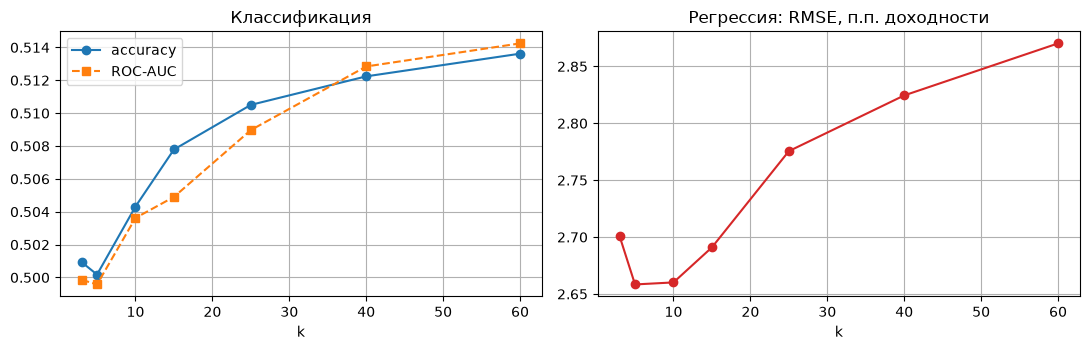

In [7]:
# --- графики: k против метрик ---
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(ks, acc, "o-", label="accuracy")
ax[0].plot(ks, auc, "s--", label="ROC-AUC")
ax[0].set_xlabel("k"); ax[0].set_title("Классификация"); ax[0].legend()
ax[1].plot(ks, rmse, "o-", color="tab:red")
ax[1].set_xlabel("k"); ax[1].set_title("Регрессия: RMSE, п.п. доходности")
plt.tight_layout(); plt.show()

## 4. Гипотеза 2: веса по расстоянию

Ближние соседи должны влиять сильнее. Сравниваем uniform и distance при k=25.

In [8]:
# --- uniform vs distance при фиксированном k ---
for w in ("uniform", "distance"):
    m_c = KNNClassifier(k=25, weights=w, chunk=512).fit(Xc_tr_s, yc_tr)
    r = metrics.classification_report(yc_te, m_c.predict(Xc_te_s), m_c.predict_proba(Xc_te_s))
    m_r = KNNRegressor(k=25, weights=w, chunk=512).fit(Xr_tr_s, yr_tr)
    rr = metrics.regression_report(yr_te, m_r.predict(Xr_te_s))
    print(f"{w:9s} accuracy={r['accuracy']:.4f} AUC={r['roc_auc']:.4f} RMSE={rr['rmse']:.4f} R2={rr['r2']:.4f}")

uniform   accuracy=0.5117 AUC=0.5100 RMSE=2.8100 R2=0.8660


distance  accuracy=0.5105 AUC=0.5090 RMSE=2.7755 R2=0.8693


## 5. Гипотеза 3: стандартизация признаков

KNN чувствителен к масштабу: `vol_rel`, `val_rel` — сотни, `ret_1` — проценты.
Проверяем качество без масштабирования.

In [9]:
# --- без стандартизации: масштаб признаков ломает метрику расстояния ---
m_raw = KNNClassifier(k=25, weights="distance", chunk=512).fit(Xc_tr, yc_tr)
r_raw = metrics.classification_report(yc_te, m_raw.predict(Xc_te), m_raw.predict_proba(Xc_te))
m_sc = KNNClassifier(k=25, weights="distance", chunk=512).fit(Xc_tr_s, yc_tr)
r_sc = metrics.classification_report(yc_te, m_sc.predict(Xc_te_s), m_sc.predict_proba(Xc_te_s))
print("без масштабирования:", round(r_raw["accuracy"], 4), "AUC", round(r_raw["roc_auc"], 4))
print("со стандартизацией: ", round(r_sc["accuracy"], 4), "AUC", round(r_sc["roc_auc"], 4))
save_result("lab1_knn", "classification", "my KNN (k=25, scaled)", r_sc)

без масштабирования: 0.5008 AUC 0.4969
со стандартизацией:  0.5105 AUC 0.509


{'lab': 'lab1_knn',
 'task': 'classification',
 'model': 'my KNN (k=25, scaled)',
 'accuracy': 0.5105,
 'precision': 0.4698,
 'recall': 0.44,
 'f1': 0.4544,
 'tp': 4580.0,
 'fp': 5168.0,
 'tn': 6890.0,
 'fn': 5830.0,
 'roc_auc': 0.509}

## Выводы

1. Своя реализация KNN совпадает со sklearn до третьего знака — код корректен.
2. Число соседей: accuracy и AUC медленно растут вплоть до k = 60, но это не
   «знание», а приближение к константной доле роста (46 %): модель всё чаще отвечает
   «вниз». RMSE регрессии при этом монотонно ухудшается (2.66 → 2.87), потому что
   усреднение по далёким соседям стирает индивидуальный уровень доходности выпуска.
3. Веса по расстоянию дают прирост только в регрессии (RMSE 2.775 против 2.810),
   в классификации разница — шум; стандартизация признаков критична: без неё
   метрика расстояния фактически определяется объёмами торгов (accuracy 0.5008 против 0.5105).
4. Абсолютные цифры скромные: accuracy ≈ 0.51, AUC ≈ 0.51 для направления цены —
   дневное направление почти не предсказуемо, KNN упирается в «потолок» данных,
   а не в реализацию. В регрессии доходности R² высокий, но он объясняется
   инерцией доходности облигации (сегодняшний уровень — лучший прогноз завтрашнего).
5. KNN непригоден для продакшена на такой панели: полный перебор 37 тыс. × 22 тыс.
   расстояний на каждый прогноз, и никакой интерпретируемости.